# 09 — Class Imbalance & Cost-Sensitive Optimization

## Loan Default Risk Classification (Binary Task)


## 1. Imports and Configuration


In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
    confusion_matrix, ConfusionMatrixDisplay
)

from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.pipeline import Pipeline as ImbPipeline

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['figure.dpi'] = 150
plt.rcParams['axes.titlesize'] = 12

RANDOM_STATE = 42

DATA_PATH = os.path.join('..', '..', 'data', 'processed', 'loan_featured.xlsx')
if not os.path.exists(DATA_PATH):
    DATA_PATH = os.path.join('data', 'processed', 'loan_featured.xlsx')

print(f'Loading data from: {DATA_PATH}')

Loading data from: ..\..\data\processed\loan_featured.xlsx


## 2. Ingestion & Preprocessing Setup


In [2]:
df = pd.read_excel(DATA_PATH, sheet_name='Loan_Featured')

# Binary target
y = (df['Loan_Default'] == 'Yes').astype(int)

# Exclude leakage
drop_cols = ['Applicant_ID', 'Application_Date', 'Risk_Category', 'Loan_Default']
X = df.drop(columns=drop_cols)

# Stratified 80/20 train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

numeric_cols = [
    'Age', 'Years_Employed', 'Annual_Income', 'Loan_Amount', 'Loan_Term_Months',
    'Interest_Rate_Pct', 'Credit_Score', 'Credit_History_Years', 'Existing_Loans',
    'Total_Credit_Limit', 'Credit_Utilization_Pct', 'Late_Payments_2Y',
    'Monthly_Debt_Payment', 'Savings_Balance', 'Checking_Balance',
    'Debt_to_Income', 'Loan_to_Income', 'Loan_to_Value', 'Savings_to_Income',
    'Log_Annual_Income', 'Log_Loan_Amount', 'Log_Savings_Balance'
]

nominal_cols = [
    'Marital_Status', 'Home_Ownership', 'Employment_Type', 'Employer_Sector',
    'Loan_Purpose', 'Region', 'Application_Channel'
]

binary_cols = [
    'Gender', 'Salary_Account_With_Bank', 'Vehicle_Owned', 'Has_Co_Applicant',
    'Previous_Default', 'Mobile_Banking_User', 'Ever_Delinquent', 'Is_Home_Loan'
]

ordinal_cols = ['Education_Level']
education_hierarchy = [['High School', 'Diploma', 'Bachelor', 'Master', 'PhD']]

# Preprocessor
preprocessor = ColumnTransformer(transformers=[
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), numeric_cols),
    ('nom', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('ohe', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))]), nominal_cols),
    ('ord', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('ord', OrdinalEncoder(categories=education_hierarchy))]), ordinal_cols),
    ('bin', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('enc', OrdinalEncoder())]), binary_cols)
], remainder='drop')


## 3. Plain vs. Balanced Logistic Regression: The Bank's Tradeoff


In [3]:
# 1. Plain Logistic Regression (threshold = 0.50)
pipe_plain = Pipeline([('prep', preprocessor), ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])
pipe_plain.fit(X_train, y_train)
y_pred_plain = pipe_plain.predict(X_test)
y_prob_plain = pipe_plain.predict_proba(X_test)[:, 1]

# 2. Balanced Logistic Regression (class_weight='balanced')
pipe_balanced = Pipeline([('prep', preprocessor), ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE))])
pipe_balanced.fit(X_train, y_train)
y_pred_bal = pipe_balanced.predict(X_test)
y_prob_bal = pipe_balanced.predict_proba(X_test)[:, 1]

# 3. SMOTE Pipeline (resampling strictly inside training pipeline)
pipe_smote = ImbPipeline([
    ('prep', preprocessor),
    ('smote', SMOTE(random_state=RANDOM_STATE)),
    ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])
pipe_smote.fit(X_train, y_train)
y_pred_smote = pipe_smote.predict(X_test)
y_prob_smote = pipe_smote.predict_proba(X_test)[:, 1]

# Comparative Results Table
df_imb = pd.DataFrame([
    {
        'Strategy': 'Plain Logistic Regression (Default 0.50)',
        'Accuracy': accuracy_score(y_test, y_pred_plain),
        'Precision': precision_score(y_test, y_pred_plain),
        'Recall': recall_score(y_test, y_pred_plain),
        'F1_Score': f1_score(y_test, y_pred_plain),
        'ROC_AUC': roc_auc_score(y_test, y_prob_plain)
    },
    {
        'Strategy': 'Class-Weighted (class_weight=balanced)',
        'Accuracy': accuracy_score(y_test, y_pred_bal),
        'Precision': precision_score(y_test, y_pred_bal),
        'Recall': recall_score(y_test, y_pred_bal),
        'F1_Score': f1_score(y_test, y_pred_bal),
        'ROC_AUC': roc_auc_score(y_test, y_prob_bal)
    },
    {
        'Strategy': 'SMOTE Pipeline (Resampled on Train Only)',
        'Accuracy': accuracy_score(y_test, y_pred_smote),
        'Precision': precision_score(y_test, y_pred_smote),
        'Recall': recall_score(y_test, y_pred_smote),
        'F1_Score': f1_score(y_test, y_pred_smote),
        'ROC_AUC': roc_auc_score(y_test, y_prob_smote)
    }
])

df_imb.to_csv('../../outputs/tables/class_imbalance_comparison.csv', index=False)
print('=== Comparison of Class Imbalance Strategies ===')
display(df_imb)


=== Comparison of Class Imbalance Strategies ===


,Strategy,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Plain Logistic Regression (Default 0.50),0.8650,0.720280,0.520202,0.604106,0.890460
1,Class-Weighted (class_weight=balanced),0.8125,0.517129,0.800505,0.628345,0.889876
2,SMOTE Pipeline (Resampled on Train Only),0.8140,0.519868,0.792929,0.628000,0.889544


## 4. Probability Threshold Shifting for >= 75% Recall


In [4]:
# Sweep probability thresholds from 0.05 to 0.90
thresholds = np.linspace(0.05, 0.90, 86)
recalls = []
precisions = []
accuracies = []
f1s = []

for t in thresholds:
    preds_t = (y_prob_plain >= t).astype(int)
    recalls.append(recall_score(y_test, preds_t))
    precisions.append(precision_score(y_test, preds_t, zero_division=0))
    accuracies.append(accuracy_score(y_test, preds_t))
    f1s.append(f1_score(y_test, preds_t))

df_sweep = pd.DataFrame({
    'Threshold': thresholds,
    'Recall': recalls,
    'Precision': precisions,
    'Accuracy': accuracies,
    'F1': f1s
})

# Find threshold achieving at least 75% recall
target_recall = 0.75
valid_thresholds = df_sweep[df_sweep['Recall'] >= target_recall]
best_thresh_row = valid_thresholds.iloc[-1]  # Highest threshold that still meets 75% recall

print('=== Operating Point for Recall >= 75% ===')
print(f'Selected Probability Threshold: theta = {best_thresh_row["Threshold"]:.2f}')
print(f'Test Recall:                    {best_thresh_row["Recall"]*100:.2f}% (Goal >= 75% achieved!)')
print(f'Precision Cost:                 {best_thresh_row["Precision"]*100:.2f}%')
print(f'Accuracy Cost:                  {best_thresh_row["Accuracy"]*100:.2f}%')
print(f'F1 Score:                       {best_thresh_row["F1"]:.4f}')


=== Operating Point for Recall >= 75% ===
Selected Probability Threshold: theta = 0.25
Test Recall:                    75.76% (Goal >= 75% achieved!)
Precision Cost:                 55.66%
Accuracy Cost:                  83.25%
F1 Score:                       0.6417


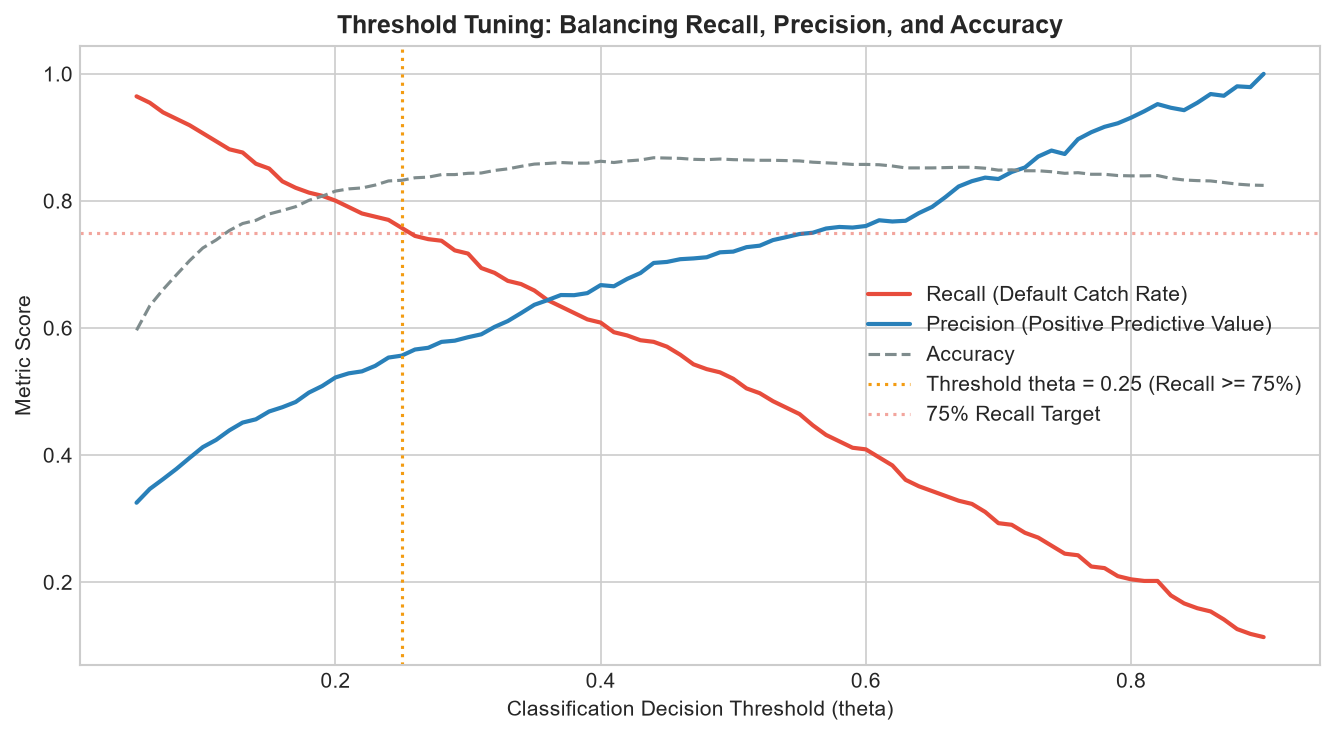

In [5]:
# Visualise Threshold Tradeoff Curves
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(thresholds, recalls, label='Recall (Default Catch Rate)', color='#e74c3c', lw=2)
ax.plot(thresholds, precisions, label='Precision (Positive Predictive Value)', color='#2980b9', lw=2)
ax.plot(thresholds, accuracies, label='Accuracy', color='#7f8c8d', linestyle='--')
ax.axvline(best_thresh_row['Threshold'], color='#f39c12', linestyle=':', label=f'Threshold theta = {best_thresh_row["Threshold"]:.2f} (Recall >= 75%)')
ax.axhline(0.75, color='#e74c3c', linestyle=':', alpha=0.5, label='75% Recall Target')

ax.set_title('Threshold Tuning: Balancing Recall, Precision, and Accuracy', weight='bold')
ax.set_xlabel('Classification Decision Threshold (theta)')
ax.set_ylabel('Metric Score')
ax.legend()

plt.tight_layout()
plt.savefig('../../outputs/figures/loan_default_threshold_tradeoff.png', dpi=150)
plt.show()


## 5. Precision-Recall Curves vs. Always-'No' Baseline


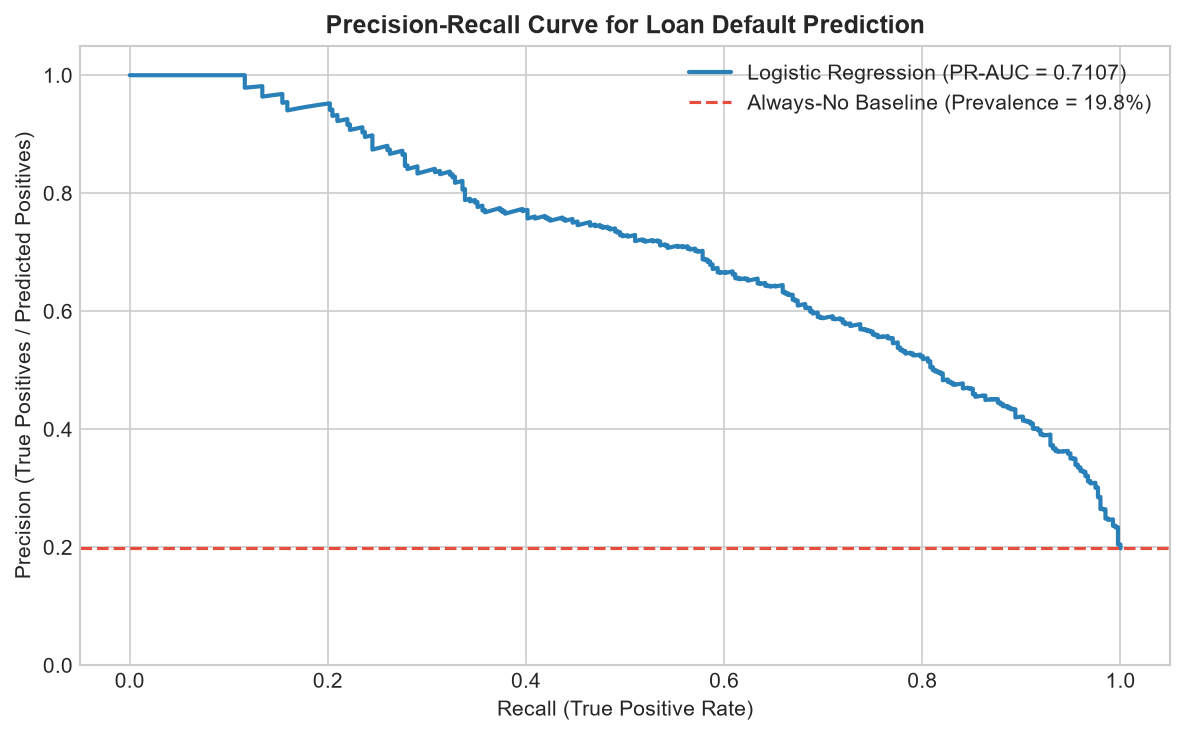

In [6]:
prec_curve, rec_curve, _ = precision_recall_curve(y_test, y_prob_plain)
pr_auc = average_precision_score(y_test, y_prob_plain)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(rec_curve, prec_curve, color='#2980b9', lw=2, label=f'Logistic Regression (PR-AUC = {pr_auc:.4f})')
ax.axhline(y_test.mean(), color='#e74c3c', linestyle='--', label=f'Always-No Baseline (Prevalence = {y_test.mean()*100:.1f}%)')

ax.set_title('Precision-Recall Curve for Loan Default Prediction', weight='bold')
ax.set_xlabel('Recall (True Positive Rate)')
ax.set_ylabel('Precision (True Positives / Predicted Positives)')
ax.set_ylim(0, 1.05)
ax.legend()

plt.tight_layout()
plt.savefig('../../outputs/figures/loan_default_pr_curve.png', dpi=150)
plt.show()

## 6. Asymmetric Business Cost Minimization


In [7]:
cost_ratio_fn = 10.0
cost_ratio_fp = 1.0

costs = []
for t in thresholds:
    preds = (y_prob_plain >= t).astype(int)
    cm_t = confusion_matrix(y_test, preds)
    # cm format: [[TN, FP], [FN, TP]]
    tn, fp, fn, tp = cm_t.ravel()
    total_cost = (cost_ratio_fn * fn) + (cost_ratio_fp * fp)
    costs.append(total_cost)

best_idx = np.argmin(costs)
optimal_theta_cost = thresholds[best_idx]
min_cost = costs[best_idx]

# Compare with default 0.50 threshold
cm_05 = confusion_matrix(y_test, (y_prob_plain >= 0.50).astype(int))
tn_05, fp_05, fn_05, tp_05 = cm_05.ravel()
cost_05 = (cost_ratio_fn * fn_05) + (cost_ratio_fp * fp_05)

df_cost_comp = pd.DataFrame([
    {
        'Operating_Threshold': 'Standard Cutoff (theta = 0.50)',
        'False_Negatives (FN)': fn_05,
        'False_Positives (FP)': fp_05,
        'Total_Cost_Units': cost_05,
        'Cost_Premium_Paid': f'+{cost_05 - min_cost:,.0f} units (+{(cost_05 - min_cost)/min_cost*100:.1f}%)'
    },
    {
        'Operating_Threshold': f'Optimal Cost Cutoff (theta = {optimal_theta_cost:.2f})',
        'False_Negatives (FN)': confusion_matrix(y_test, (y_prob_plain >= optimal_theta_cost).astype(int))[1, 0],
        'False_Positives (FP)': confusion_matrix(y_test, (y_prob_plain >= optimal_theta_cost).astype(int))[0, 1],
        'Total_Cost_Units': min_cost,
        'Cost_Premium_Paid': 'Minimum Expected Cost (Optimal Baseline)'
    }
])

df_cost_comp.to_csv('../../outputs/tables/cost_optimal_threshold_comparison.csv', index=False)
print('=== Financial Loss Minimization: Optimal vs. 0.50 Threshold ===')
display(df_cost_comp)


=== Financial Loss Minimization: Optimal vs. 0.50 Threshold ===


,Operating_Threshold,False_Negatives (FN),False_Positives (FP),Total_Cost_Units,Cost_Premium_Paid
0,Standard Cutoff (theta = 0.50),190,80,1980.0,"+1,104 units (+126.0%)"
1,Optimal Cost Cutoff (theta = 0.09),32,556,876.0,Minimum Expected Cost (Optimal Baseline)


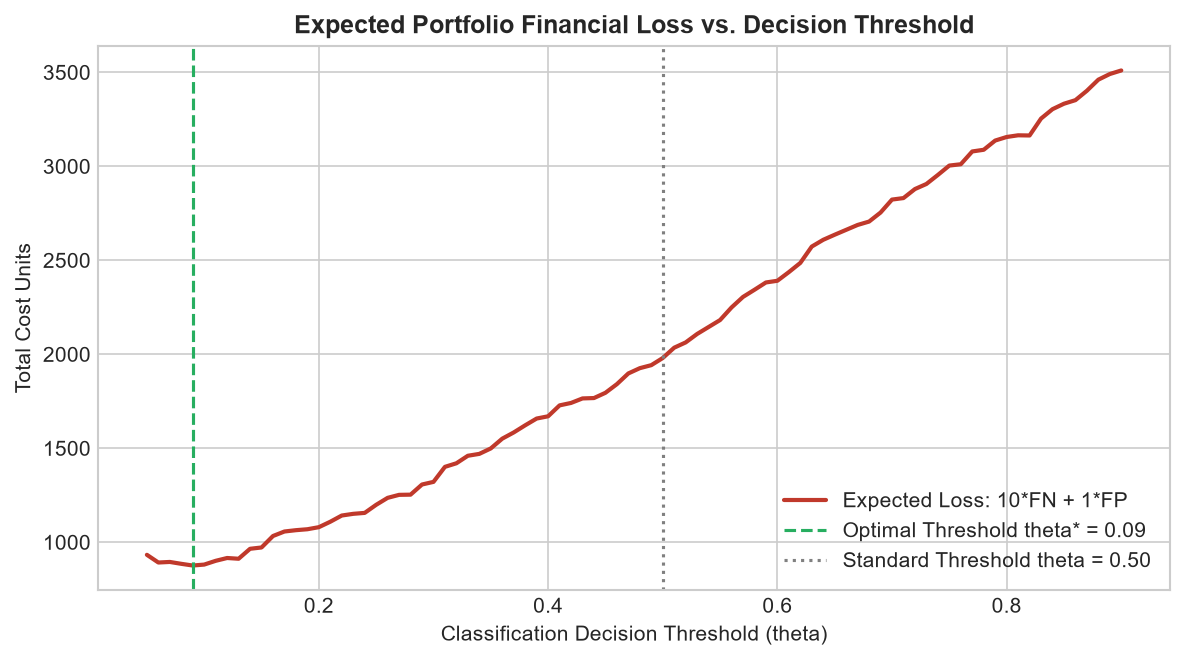

In [8]:
# Visualise Cost Curve
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(thresholds, costs, color='#c0392b', lw=2, label='Expected Loss: 10*FN + 1*FP')
ax.axvline(optimal_theta_cost, color='#27ae60', linestyle='--', label=f'Optimal Threshold theta* = {optimal_theta_cost:.2f}')
ax.axvline(0.50, color='gray', linestyle=':', label='Standard Threshold theta = 0.50')

ax.set_title('Expected Portfolio Financial Loss vs. Decision Threshold', weight='bold')
ax.set_xlabel('Classification Decision Threshold (theta)')
ax.set_ylabel('Total Cost Units')
ax.legend()

plt.tight_layout()
plt.savefig('../../outputs/figures/loan_default_cost_curve.png', dpi=150)
plt.show()